In [2]:
import numpy as np
import math
import torch as t

In [3]:
words = open("names.txt").read().splitlines()

In [4]:
words[:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [5]:
chars = "abcdefghijklmnopqrstuvwxyz"
stoi = {c: i for i, c in enumerate(chars)}      # char -> index, a=0 b=1 ...
stoi["."] = 26                                  # add boundary token
itos = {i: c for c, i in stoi.items()}          # reverse mapping

In [14]:
# Desired 
# ... → e
# ..e → m
# .em → m
# emm → a
# mma → .

In [19]:
xs = []
ys = []
n = 0
block_size = 3
for w in words:
    padded = w + "."
    context = [stoi["."]] * block_size
    for i in range(0,len(padded)):
        xs.append(context)
        ix = stoi[padded[i]]
        ys.append(ix)
        context = context[1:] + [ix]
        n += 1

In [22]:
print(xs[:5])
print(ys[:5])

[[26, 26, 26], [26, 26, 4], [26, 4, 12], [4, 12, 12], [12, 12, 0]]
[4, 12, 12, 0, 26]


In [25]:
X = t.tensor(xs)
Y = t.tensor(ys)
print(X.shape)
print(Y.shape)

torch.Size([228146, 3])
torch.Size([228146])


In [27]:
# Embedding matrix - just 2-d to begin with
# Each char represented by 2 scalars
C = t.randn(27, 2)

In [28]:
# Embeddings for the entire X brought together
# Each row of X has 3 chars; each char is 2 dimensional

emb = C[X]

In [29]:
# So the shape of emb should be N x 3 x 2
print (emb.shape)

torch.Size([228146, 3, 2])


In [35]:
# Let's confirm

# X[1] is 3 chars "..e" (from ...emma.)

# . is
print(C[26])

# e is 
print(C[4])

# emb[1] should be 3 x 2: 2 dots and 1 e
print(emb[1])


tensor([-0.4963,  1.3479])
tensor([1.1597, 2.0626])
tensor([[-0.4963,  1.3479],
        [-0.4963,  1.3479],
        [ 1.1597,  2.0626]])


In [ ]:
# Add a non-linear hidden layer
# h=tanh(x.W1+b1)
# create W1 with t.randn(6, h) and b1 with t.randn(h)
# compute the hidden activations with view, @, +, and t.tanh in one expression, and confirm the shape is (N,h)

In [37]:
# Hidden layer dimensionality
h = 100

In [44]:
W1 = t.randn(6,h)
print(W1.shape)
b1 = t.randn(h)
print(b1.shape)

torch.Size([6, 100])
torch.Size([100])


In [43]:
# emb is of shape (N,3,2)
# for matrix multiplication we want the 3x2 to be flattened to one vector of 6
x_flat = emb.view(-1, 6) # -1 infers the shape, instead of us having to pass N
print(x_flat.shape)

torch.Size([228146, 6])


In [45]:
h1 = t.tanh(x_flat @ W1 + b1)
print(h1.shape)

torch.Size([228146, 100])


In [47]:
print(h1[:2,:2])

tensor([[-0.9053,  0.9883],
        [-0.7379, -0.9829]])


In [ ]:
# Now the logits
# Shape - (N, 27)
# i.e. for each example N, a raw value vector for each of the 27 chars (which becomes probability after softmax)

In [48]:
W2 = t.randn(h, 27)
b2 = t.randn(27)

In [49]:
logits = h1 @ W2 + b2

In [50]:
print(logits.shape)

torch.Size([228146, 27])


In [51]:
import torch.nn.functional as F

In [52]:
NLL_torch = F.cross_entropy(logits, Y)

In [53]:
NLL_torch

tensor(15.6575)

In [57]:
exp = t.exp(logits)
row_sums = exp.sum(dim=1, keepdim=True)
probs = exp/row_sums
loss = -t.log(probs[t.arange(n), ys]).mean()
print(loss)

In [62]:
# Retry with smaller starting weights
W2 = t.randn(h, 27) * 0.01
b2 = t.zeros(27)
logits = h1 @ W2 + b2
F.cross_entropy(logits, Y)

tensor(3.2938)

In [63]:
t.manual_seed(42)


In [64]:
# ---- parameters (fresh, all tracked by autograd) ----
n_hidden = 100

C  = t.randn(27, 2,          requires_grad=True)
W1 = t.randn(6, n_hidden,    requires_grad=True)
b1 = t.randn(n_hidden,       requires_grad=True)
W2 = (t.randn(n_hidden, 27) * 0.01).requires_grad_()   # small: honest start
b2 = t.zeros(27,             requires_grad=True)

In [65]:
parameters = [C, W1, b1, W2, b2]
print("parameter count:", sum(p.nelement() for p in parameters))

parameter count: 3481


In [67]:
# ---- hyperparameters ----
lr         = 0.1
batch_size = 32
steps      = 10_000
lossi      = []

In [75]:
# ---- training loop ----
for step in range(steps):

    # 1. sample a minibatch
    ix = t.randint(0, X.shape[0], (batch_size,))
    Xb, Yb = X[ix], Y[ix]

    # 2. forward pass
    emb    = C[Xb]                          # (32, 3, 2)
    h1     = t.tanh(emb.view(-1, 6) @ W1 + b1)   # (32, 100)
    logits = h1 @ W2 + b2                   # (32, 27)
    loss   = F.cross_entropy(logits, Yb)

    # 3. backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # 4. update
    with t.no_grad():
        for p in parameters:
            p -= lr * p.grad

    # 5. track
    lossi.append(loss.item())
    if step % 1000 == 0:
        print(step, round(loss.item(), 4))

0 3.3079
1000 2.2803
2000 2.5906
3000 2.414
4000 2.0798
5000 2.5343
6000 2.1717
7000 2.1668
8000 2.3671
9000 2.4003


In [76]:
# ---- loss over the FULL dataset ----
with t.no_grad():
    emb    = C[X]
    h1     = t.tanh(emb.view(-1, 6) @ W1 + b1)
    logits = h1 @ W2 + b2
    full_loss = F.cross_entropy(logits, Y)
print("full dataset loss:", round(full_loss.item(), 4))

full dataset loss: 2.3278


# Step 6

In [91]:
def build_dataset(word_list):  
    xs = []
    ys = []
    block_size = 3
    for w in word_list:
        padded = w + "."
        context = [stoi["."]] * block_size
        for i in range(0,len(padded)):
            xs.append(context)
            ix = stoi[padded[i]]
            ys.append(ix)
            context = context[1:] + [ix]
    X = t.tensor(xs)
    Y = t.tensor(ys)
    return X, Y

In [92]:
import random
random.seed(42)
random.shuffle(words)

In [93]:
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

In [94]:
Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

In [95]:
t.manual_seed(42)

# ---- parameters (fresh, all tracked by autograd) ----
n_hidden = 100

C  = t.randn(27, 2,          requires_grad=True)
W1 = t.randn(6, n_hidden,    requires_grad=True)
b1 = t.randn(n_hidden,       requires_grad=True)
W2 = (t.randn(n_hidden, 27) * 0.01).requires_grad_()   # small: honest start
b2 = t.zeros(27,             requires_grad=True)

parameters = [C, W1, b1, W2, b2]
print("parameter count:", sum(p.nelement() for p in parameters))

# ---- hyperparameters ----
lr = 0.1 if step < 0.8 * steps else 0.01
batch_size = 32
steps      = 10_000
lossi      = []


parameter count: 3481


In [107]:
def train(X, Y):
    # ---- training loop ----
    for step in range(steps):
    
        # 1. sample a minibatch
        ix = t.randint(0, X.shape[0], (batch_size,))
        Xb, Yb = X[ix], Y[ix]
    
        # 2. forward pass
        emb    = C[Xb]                          # (32, 3, 2)
        h1     = t.tanh(emb.view(-1, n_in) @ W1 + b1)   # (32, 100)
        logits = h1 @ W2 + b2                   # (32, 27)
        loss   = F.cross_entropy(logits, Yb)
    
        # 3. backward pass
        for p in parameters:
            p.grad = None
        loss.backward()
    
        # 4. update
        with t.no_grad():
            for p in parameters:
                p -= lr * p.grad
    
        # 5. track
        lossi.append(loss.item())
        if step % 1000 == 0:
            print(step, round(loss.item(), 4))

def test(X, Y):
    # ---- honest number: loss over the FULL dataset ----
    with t.no_grad():
        emb    = C[X]
        h1     = t.tanh(emb.view(-1, n_in) @ W1 + b1)
        logits = h1 @ W2 + b2
        full_loss = F.cross_entropy(logits, Y)
    print("full dataset loss:", round(full_loss.item(), 4))

In [97]:
train(Xtr, Ytr)

0 3.3048
1000 2.2843
2000 2.2613
3000 2.1292
4000 2.046
5000 2.361
6000 2.349
7000 2.3956
8000 2.563
9000 1.9525


In [99]:
test(Xtr, Ytr)

full dataset loss: 2.3361


In [98]:
test(Xdev, Ydev)

full dataset loss: 2.3454


# Step 7

Matplotlib is building the font cache; this may take a moment.


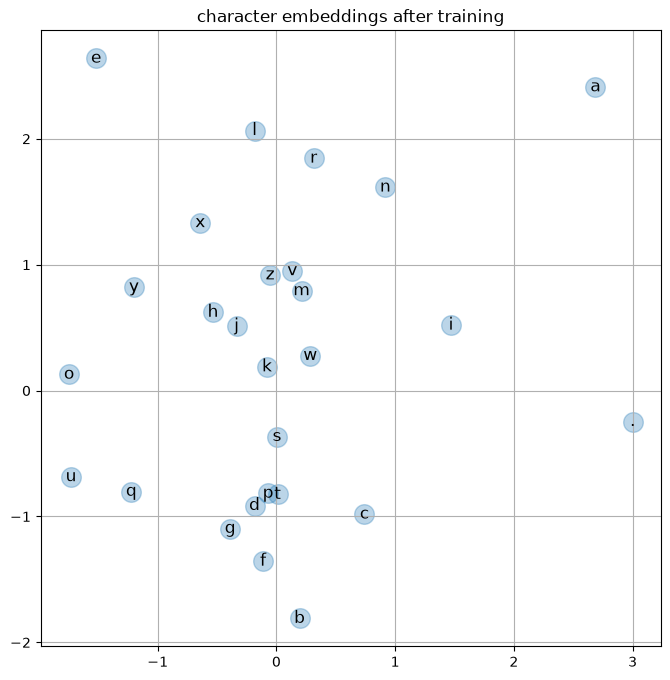

In [101]:
# ---- step 7a: plot the learned 2-d embeddings ----
import matplotlib.pyplot as plt

Cn = C.detach().numpy()          # detach from autograd, convert to numpy

plt.figure(figsize=(8, 8))
plt.scatter(Cn[:, 0], Cn[:, 1], s=200, alpha=0.3)
for i in range(27):
    plt.text(Cn[i, 0], Cn[i, 1], itos[i], ha="center", va="center", fontsize=12)
plt.grid(True)
plt.title("character embeddings after training")
plt.show()

In [102]:
# ---- step 7b: sample 20 names from the model ----
with t.no_grad():
    for _ in range(20):
        context = [stoi["."]] * 3            # start: all boundary tokens
        out = []
        while True:
            emb    = C[t.tensor([context])]  # shape (1, 3, 2) — batch of one
            h1     = t.tanh(emb.view(-1, 6) @ W1 + b1)
            logits = h1 @ W2 + b2
            probs  = F.softmax(logits, dim=1)            # (1, 27)
            ix     = t.multinomial(probs, num_samples=1).item()  # draw one index
            if ix == stoi["."]:              # boundary drawn: name finished
                break
            out.append(itos[ix])
            context = context[1:] + [ix]     # slide the window
        print("".join(out))

amanna
cheshin
mase
ay
ioen
bro
hare
shilynna
trin
sen
kyana
muvak
mariviyshah
pa
kayoyal
kaa
jermia
nce
rahdran
fthaymie


# Step 8

In [104]:
# ---- step 8: scale up ----
t.manual_seed(42)

n_emb    = 10        # DECISION: embedding dimension (was 2)
n_hidden = 100       # DECISION: hidden size
steps    = 50_000    # DECISION: training length
n_in     = block_size * n_emb    # hidden layer input width, no more hardcoded 6

C  = t.randn(27, n_emb,       requires_grad=True)
W1 = t.randn(n_in, n_hidden,  requires_grad=True)
b1 = t.randn(n_hidden,        requires_grad=True)
W2 = (t.randn(n_hidden, 27) * 0.01).requires_grad_()
b2 = t.zeros(27,              requires_grad=True)
parameters = [C, W1, b1, W2, b2]
print("parameter count:", sum(p.nelement() for p in parameters))

batch_size = 32
lossi = []

parameter count: 6097


In [105]:
train(Xtr, Ytr)

0 3.2741
1000 2.2507
2000 2.2977
3000 2.4472
4000 2.1723
5000 2.4315
6000 2.5876
7000 2.1306
8000 2.5882
9000 2.4624
10000 2.1751
11000 2.1528
12000 2.0637
13000 2.025
14000 1.7084
15000 2.41
16000 2.3613
17000 2.7005
18000 2.156
19000 1.71
20000 2.1869
21000 2.4968
22000 2.4519
23000 2.7152
24000 2.4456
25000 1.8369
26000 1.953
27000 2.4377
28000 2.649
29000 2.7224
30000 2.061
31000 2.4212
32000 2.1979
33000 2.0874
34000 2.1033
35000 2.2034
36000 2.3953
37000 2.1906
38000 2.6946
39000 2.0516
40000 2.4205
41000 2.0788
42000 2.7681
43000 1.9909
44000 2.5339
45000 2.1659
46000 2.4033
47000 2.1104
48000 2.026
49000 2.4044


In [109]:
test(Xtr, Ytr)
test(Xdev, Ydev)

full dataset loss: 2.2116
full dataset loss: 2.2439


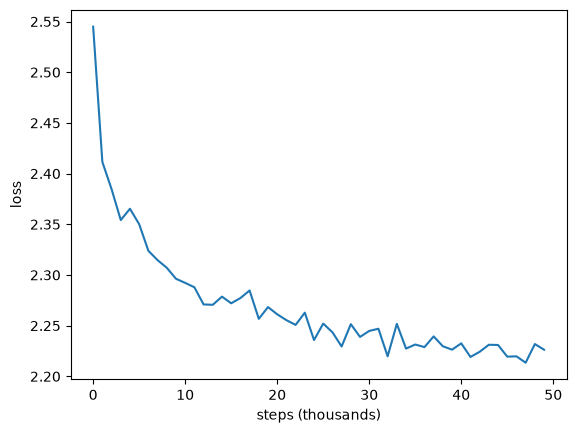

In [110]:
# ---- loss curve: minibatch noise makes raw lossi unreadable, so average
# ---- consecutive chunks of 1000 steps into one point each
import matplotlib.pyplot as plt
smoothed = t.tensor(lossi).view(-1, 1000).mean(dim=1)
plt.plot(smoothed)
plt.xlabel("steps (thousands)")
plt.ylabel("loss")
plt.show()

In [111]:
test(Xte, Yte)

full dataset loss: 2.2552


In [ ]:
# class MyModel:
#     # ---- parameters (fresh, all tracked by autograd) ----
#     n_hidden = 100
    
#     C  = t.randn(27, 2,          requires_grad=True)
#     W1 = t.randn(6, n_hidden,    requires_grad=True)
#     b1 = t.randn(n_hidden,       requires_grad=True)
#     W2 = (t.randn(n_hidden, 27) * 0.01).requires_grad_()   # small: honest start
#     b2 = t.zeros(27,             requires_grad=True)
    
#     parameters = [C, W1, b1, W2, b2]
#     print("parameter count:", sum(p.nelement() for p in parameters))
    
#     # ---- hyperparameters ----
#     lr         = 0.1
#     batch_size = 32
#     steps      = 10_000
#     lossi      = []
    
#     @staticmethod
#     def train(X, Y):
#         t.manual_seed(42)
        
#         # ---- training loop ----
#         for step in range(steps):
        
#             # 1. sample a minibatch
#             ix = t.randint(0, X.shape[0], (batch_size,))
#             Xb, Yb = X[ix], Y[ix]
        
#             # 2. forward pass
#             emb    = C[Xb]                          # (32, 3, 2)
#             h1     = t.tanh(emb.view(-1, 6) @ W1 + b1)   # (32, 100)
#             logits = h1 @ W2 + b2                   # (32, 27)
#             loss   = F.cross_entropy(logits, Yb)
        
#             # 3. backward pass
#             for p in parameters:
#                 p.grad = None
#             loss.backward()
        
#             # 4. update
#             with t.no_grad():
#                 for p in parameters:
#                     p -= lr * p.grad
        
#             # 5. track
#             lossi.append(loss.item())
#             if step % 1000 == 0:
#                 print(step, round(loss.item(), 4))
    
#     @staticmethod
#     def test(X,Y):
#         # ---- honest number: loss over the FULL dataset ----
#         with t.no_grad():
#             emb    = C[X]
#             h1     = t.tanh(emb.view(-1, 6) @ W1 + b1)
#             logits = h1 @ W2 + b2
#             full_loss = F.cross_entropy(logits, Y)
#         print("full dataset loss:", round(full_loss.item(), 4))